In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "2"
os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"] = "0.95"

In [2]:
import matplotlib.pyplot as plt
%matplotlib inline
import jax
import jax.numpy as jnp
import jax.random as jr
import optax
import math
import time

import k3d
import numpy as np
from matplotlib.colors import ListedColormap
from typing import Callable
from functools import partial

from implicitSurfaces.lipschitzImplicit import sdfImplicit
from implicitSurfaces.harmonicImplicit import poissonSurface
from implicitSurfaces.sdf_primitives import sphere_sdf, bbox_sdf, arc2d
from sphereWalker.integrator import WoSIntegrator, DifferentialWoSIntegrator
from sphereWalker.sampling import sample_uniform_1sphere
from utils.losses import volume_integral_loss_grad, surface_integral_loss_grad, l2_loss, dL2_du, surface_integral_loss_grad_normalized
from utils.tree_ops import binary_tree_op, accumulate_weighted_trees
import operator
from utils.helpers import mesh_2d

In [3]:
jax.config.update("jax_debug_nans", True)

In [4]:
def smily_sdf(params, x):
    outer_boundary = bbox_sdf({'min_corner': jnp.array([-1., -1.]), 'max_corner': jnp.array([1., 1.])}, x)
    left_eye = sphere_sdf({'center': jnp.array([-0.5, 0.5]), 'radius': jnp.array(0.2)}, x)
    right_eye = sphere_sdf({'center': jnp.array([0.5, 0.5]), 'radius': jnp.array(0.2)}, x)
    tb = 3.14 * (0.25 + 0.5 * 0.1)
    mouth = arc2d({'sc': jnp.array([jnp.sin(tb), jnp.cos(tb)]), 'ra': jnp.array(0.65), 'rb': jnp.array(0.12)}, -x)
    eyes_and_mouth = jnp.minimum(jnp.minimum(left_eye, right_eye), mouth)
    return jnp.maximum(outer_boundary, -eyes_and_mouth)


In [5]:
bbox_sdf({'min_corner': jnp.array([-1., -1.]), 'max_corner': jnp.array([1., 1.])}, jnp.array([0., 0.]))

Array(-0.999999, dtype=float32)

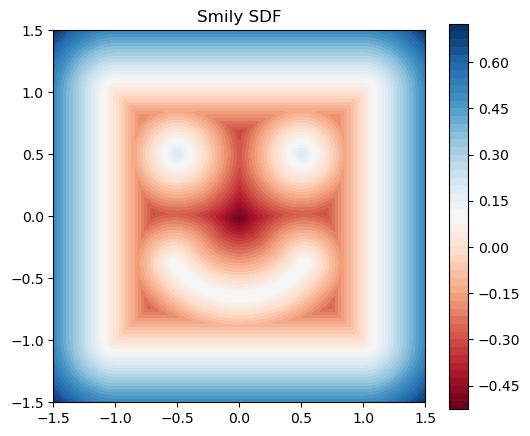

In [37]:
X, Y = mesh_2d(128, ((-1.5, 1.5), (-1.5, 1.5)))
points = jnp.stack([X, Y], axis=-1).reshape(-1, 2)

fig = plt.figure(figsize=(6, 5))
ax = fig.add_subplot(111)
contouf = ax.contourf(X, Y, jax.vmap(smily_sdf)(None, points).reshape(X.shape), levels=50, cmap='RdBu')
ax.set_aspect('equal')
ax.set_title('Smily SDF')
plt.colorbar(contouf)
plt.show()

In [38]:
def sum_of_circles_sdf(params, x):
    dist = jnp.inf
    for circ_param in params:
        dist = jnp.minimum(dist, sphere_sdf(circ_param, x))
    return dist

In [102]:
surface_params = poissonSurface.init_monopole_field(jr.PRNGKey(0), bbox=((-0.5, 0.5), (-0.5, 0.5)), num_points=25)
radii = jnp.ones((surface_params['p'].shape[0],)) * 0.05
to_opt_params = tuple({'center': surface_params['p'][i], 'radius': radii[i]} for i in range(surface_params['p'].shape[0]))
outer_boundary = lambda params, x: bbox_sdf({'min_corner': jnp.array([-1., -1.]), 'max_corner': jnp.array([1., 1.])}, x)
#outer_boundary = lambda params, x: sphere_sdf({'center': jnp.array([0.0000, 0.0000]), 'radius': jnp.array(1.5)}, x)
composed_field_fn = lambda p, x: jnp.maximum(-sum_of_circles_sdf(p, x), outer_boundary(p, x))
#composed_field_fn = lambda p, x: jnp.maximum(-sphere_sdf(p, x), outer_boundary(p, x))

to_opt_surface = sdfImplicit(dim=2, fn=composed_field_fn)

In [40]:
fn_vals = jax.vmap(to_opt_surface, in_axes=(None, 0))(to_opt_params, points).reshape(X.shape)
fn_vals.min(), fn_vals.max()

(Array(-0.2755745, dtype=float32), Array(0.70710677, dtype=float32))

/tmp/ipykernel_370041/1640355471.py:1: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(surface_params['p'][:, 0], surface_params['p'][:, 1], cmap='viridis')


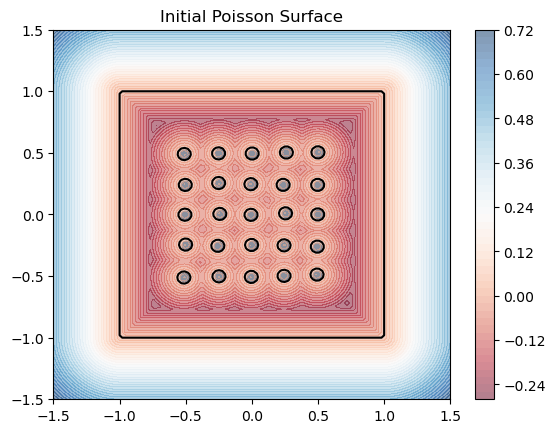

In [41]:
plt.scatter(surface_params['p'][:, 0], surface_params['p'][:, 1], cmap='viridis')
contouf = plt.contourf(X, Y, jax.vmap(to_opt_surface, in_axes=(None, 0))(to_opt_params, points).reshape(X.shape), levels=50, cmap='RdBu', alpha=0.5)
contour = plt.contour(X, Y, jax.vmap(to_opt_surface, in_axes=(None, 0))(to_opt_params, points).reshape(X.shape), levels=[to_opt_surface.level_set], colors='black')
plt.colorbar(contouf)
surf_points = jax.vmap(lambda key: sample_uniform_1sphere(key, jnp.float32))(jax.random.split(jax.random.PRNGKey(0), 1000)) * 0.95
surface_velocities = jax.vmap(to_opt_surface.normal_at, in_axes=(None, 0))(to_opt_params, surf_points)
surf_points2 = jnp.vstack((jnp.linspace(-1., 1., 100), jnp.ones((100,)))).T
surface_velocities2 = jax.vmap(to_opt_surface.normal_at, in_axes=(None, 0))(to_opt_params, surf_points2)
#plt.quiver(surf_points[:, 0], surf_points[:, 1], surface_velocities[:, 0], surface_velocities[:, 1], color='black', width=0.002)
#plt.quiver(surf_points2[:, 0], surf_points2[:, 1], surface_velocities2[:, 0], surface_velocities2[:, 1], color='red', width=0.002)
plt.title('Initial Poisson Surface')
plt.show()

In [42]:
def const_source_fn(x):
    return 4.0

def zero_boundary_condition(point: jnp.ndarray) -> jnp.ndarray:
    return 0.0

In [43]:
X, Y = mesh_2d(512, ((-1.5, 1.5), (-1.5, 1.5)))
opt_loop_points = jnp.stack([X, Y], axis=-1).reshape(-1, 2)
inside_reference_mask = jax.vmap(smily_sdf)(None, opt_loop_points) < 0

In [44]:
key = jax.random.PRNGKey(0)
N = 10000
ref_fn = smily_sdf
#ref_fn = lambda p, x: jnp.maximum(-sphere_sdf({'center': jnp.array([0., 0.]), 'radius': 0.3}, x), outer_boundary(None, x))
reference_surface = sdfImplicit(fn=ref_fn, dim=2)

reference_solver = WoSIntegrator(
    empty_sphere_fn=reference_surface.empty_sphere, 
    boundary_condition_fn=zero_boundary_condition,
    source_term_fn=const_source_fn,
    dim=2,
    level_set=0.0,
    eps=1e-3,
    max_steps=1000,
    print_progress=False
)

inside_reference_mask = jax.vmap(reference_surface)(None, opt_loop_points) < 0
reference_estimate = reference_solver.integrate_batch(None, opt_loop_points[inside_reference_mask], rng_key=jax.random.PRNGKey(2), init_trust_region_size=jnp.inf, n_samples=512)
reference_estimate_full = jnp.zeros((opt_loop_points.shape[0], 1))
reference_estimate_full = reference_estimate_full.at[inside_reference_mask].set(reference_estimate.w)

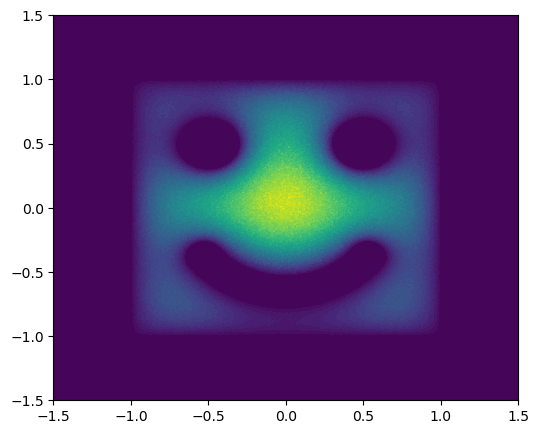

In [45]:
fig = plt.figure(figsize=(6, 5))
ax = fig.add_subplot(111)

contouf = ax.contourf(X, Y, reference_estimate_full.squeeze().reshape(X.shape), levels=50)
#ax.scatter(opt_loop_points[inside_reference_mask, 0], opt_loop_points[inside_reference_mask, 1])

In [46]:
def sgd_step(params, opt_state, grads, optimizer):
    updates, new_opt_state = optimizer.update(grads, opt_state)
    params_new = optax.apply_updates(params, updates)
    return params_new, new_opt_state

In [81]:
dif_integrator = DifferentialWoSIntegrator(
    empty_sphere_fn=to_opt_surface.empty_sphere, 
    boundary_condition_fn=zero_boundary_condition,
    source_term_fn=const_source_fn,
    Df=to_opt_surface.dirichlet_boundary_differential,
    V_n=to_opt_surface.normal_surface_velocity,
    normal_fn=to_opt_surface.normal_at,
    offset_l=0.01,
    dim=to_opt_surface.dim,
    level_set=to_opt_surface.level_set,
    eps=1e-3,
    max_steps=1000,
    print_progress=False,
)

primary_integrator = WoSIntegrator(
    empty_sphere_fn=to_opt_surface.empty_sphere, 
    boundary_condition_fn=zero_boundary_condition,
    source_term_fn=const_source_fn,
    dim=to_opt_surface.dim,
    level_set=to_opt_surface.level_set,
    eps=1e-3,
    max_steps=1000,
    print_progress=False
)


optimizer = optax.sgd(learning_rate=10)
opt_state = optimizer.init(to_opt_params)

# param_labels = {
#     'center': 'train',
#     'radius': 'train'  # Label this one 'fixed'
# }
# optimizer = optax.multi_transform(
#     {
#         'train': optax.sgd(learning_rate=0.3, momentum=0.9),
#         'fixed': optax.set_to_zero()  # Explicitly zero out updates
#     },
#     param_labels
# )
opt_state = optimizer.init(to_opt_params)

DOMAIN_AREA = (X.max() - X.min()) * (Y.max() - Y.min())
TARGET_MIN_VOLUME = DOMAIN_AREA * inside_reference_mask.mean() * 0.75
EPSILON = 1e-3
LAMBDA_VOL = 0.1

u_solution_full = jnp.zeros((opt_loop_points.shape[0]))
du_dtheta_full = jax.tree.map(
    lambda x: jnp.zeros((opt_loop_points.shape[0], *x.shape)), 
    to_opt_params
)

In [48]:
init_inside = jax.vmap(composed_field_fn, in_axes=(None, 0))(to_opt_params, opt_loop_points) < to_opt_surface.level_set

init_estimate = primary_integrator.integrate_batch(to_opt_params, opt_loop_points[init_inside], rng_key=jax.random.PRNGKey(2), init_trust_region_size=jnp.inf, n_samples=512)
init_estimate_full = jnp.zeros((opt_loop_points.shape[0], 1))
init_estimate_full = init_estimate_full.at[init_inside].set(init_estimate.w)

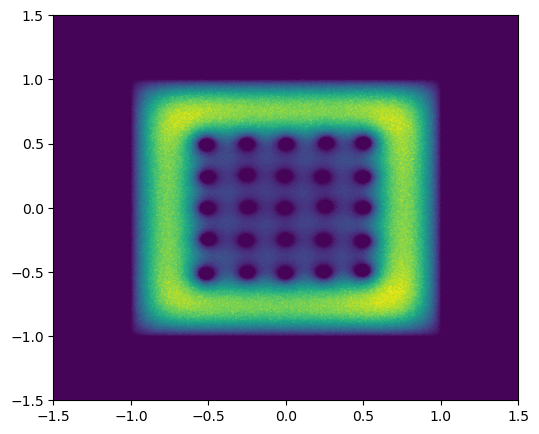

In [49]:
fig = plt.figure(figsize=(6, 5))
ax = fig.add_subplot(111)

contouf = ax.contourf(X, Y, init_estimate_full.squeeze().reshape(X.shape), levels=50)

In [82]:
def min_volume_loss(fn: Callable,
                    params,  
                    domain_samples: jnp.ndarray, 
                    domain_volume: float, 
                    min_volume: float, 
                    temperature: float = 20.0):
    """
    Penalizes the implicit surface ONLY if its volume drops below min_volume.
    Uses a volumetric approximation (soft Heaviside) to be differentiable.
    
    Args:
        params: Surface parameters.
        fn: Function signature fn(params, x) -> float.
        domain_samples: (N, dim) points sampled uniformly in the simulation box.
        domain_volume: Total volume of the bounding box where samples were drawn.
        min_volume: The minimum required volume for the shape.
        temperature: Controls sharpness of the boundary approximation. 
                     Higher = more accurate volume, sharper gradients.
                     Lower = smoother gradients, helps recovery from vanishing.
    
    Returns:
        Scalar loss. 0.0 if volume >= min_volume. Positive otherwise.
    """
    fn_values = jax.vmap(fn, in_axes=(None, 0))(params, domain_samples).squeeze()
    occupancy = jax.nn.sigmoid(-temperature * fn_values)
    current_volume = jnp.mean(occupancy) * domain_volume
    volume_deficit = jax.nn.relu(min_volume - current_volume)
    
    return jnp.square(volume_deficit)

In [51]:
min_volume_loss(to_opt_surface, to_opt_params, opt_loop_points, domain_volume=(X.max() - X.min()) * (Y.max() - Y.min()), min_volume=TARGET_MIN_VOLUME)

Array(0., dtype=float32)

Iter 0: Omega pts: 99365 | Boundary pts: 212
  -> Total Loss: 0.000361
  [Timing] Geo: 2.7096s | Vol: 0.6657s | Phys: 24.5757s | Reyn: 0.4944s | Upd: 0.0645s | Total: 28.5102s
Iter 1: Omega pts: 100975 | Boundary pts: 93
  -> Total Loss: 0.000422
  [Timing] Geo: 2.7496s | Vol: 0.6683s | Phys: 25.6301s | Reyn: 0.5337s | Upd: 0.0752s | Total: 29.6572s
Iter 2: Omega pts: 99280 | Boundary pts: 238
  -> Total Loss: 0.000357
  [Timing] Geo: 2.6995s | Vol: 0.6487s | Phys: 12.9605s | Reyn: 0.9246s | Upd: 0.0638s | Total: 17.2975s
Iter 3: Omega pts: 100805 | Boundary pts: 94
  -> Total Loss: 0.000384
  [Timing] Geo: 2.7107s | Vol: 0.6538s | Phys: 13.5619s | Reyn: 0.9376s | Upd: 0.0653s | Total: 17.9298s
Iter 4: Omega pts: 99382 | Boundary pts: 233
  -> Total Loss: 0.000325
  [Timing] Geo: 2.6595s | Vol: 0.6597s | Phys: 12.6822s | Reyn: 0.5350s | Upd: 0.0656s | Total: 16.6024s
Iter 5: Omega pts: 100544 | Boundary pts: 97
  -> Total Loss: 0.000336
  [Timing] Geo: 2.6453s | Vol: 0.6449s | Phys: 13

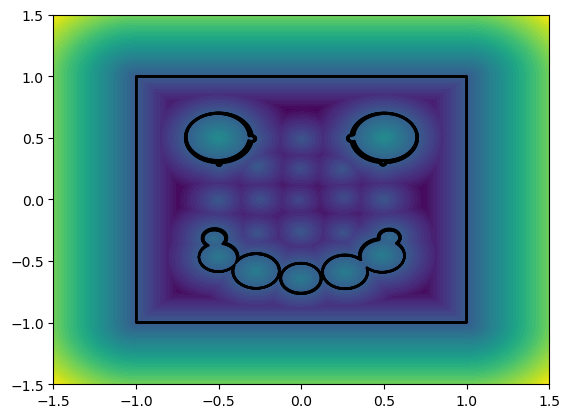

In [113]:


# --- Training Loop ---
for i in range(10):
    t_start = time.time()
    
    # --- Phase A: Geometry & Masks ---
    t0 = time.time()
    sdf_val = jax.vmap(to_opt_surface, in_axes=(None, 0))(to_opt_params, opt_loop_points)
    sdf_grad = jax.vmap(to_opt_surface.spatial_derivative, in_axes=(None, 0))(to_opt_params, opt_loop_points)
    normal_velocity = jax.vmap(to_opt_surface.normal_surface_velocity, in_axes=(None, 0))(to_opt_params, opt_loop_points)
    
    omega_mask = sdf_val < to_opt_surface.level_set
    intersection_mask = jnp.logical_and(inside_reference_mask, omega_mask)
    boundary_mask = jnp.logical_and(inside_reference_mask, jnp.abs(sdf_val - to_opt_surface.level_set) < EPSILON)

    # Force synchronization to measure calc time
    N_omega = omega_mask.sum().block_until_ready()
    N_boundary = boundary_mask.sum().block_until_ready()
    
    vol_approx_intersection = DOMAIN_AREA * intersection_mask.mean()
    vol_approx_omega = DOMAIN_AREA * omega_mask.mean()
    vol_approx_boundary = DOMAIN_AREA * boundary_mask.mean()
    t_geo = time.time() - t0

    print(f"Iter {i}: Omega pts: {N_omega} | Boundary pts: {N_boundary}")

    # --- Phase B: Volume Regularization Gradient ---
    t0 = time.time()
    grad_volume = jax.grad(min_volume_loss, argnums=1)(
        to_opt_surface, 
        to_opt_params, 
        opt_loop_points, 
        domain_volume=DOMAIN_AREA, 
        min_volume=TARGET_MIN_VOLUME
    )
    # Block on a leaf of the gradient tree to ensure computation finished
    jax.tree.leaves(grad_volume)[0].block_until_ready()
    t_vol = time.time() - t0

    # --- Phase C: Physics (Monte Carlo Integration) ---
    t0 = time.time()
    if N_omega == 0:
        print(f"  -> Skipping step: No points inside domain.")
        break 

    active_points = opt_loop_points[omega_mask]
    rng_key = jax.random.PRNGKey(i)
    
    u_estimate = primary_integrator.integrate_batch(
        to_opt_params, active_points, rng_key=rng_key, 
        init_trust_region_size=jnp.inf, n_samples=256, steps_between_refill=100, jit_buck_size=10000
    )
    
    du_estimate = dif_integrator.integrate_batch(
        to_opt_params, active_points, rng_key=rng_key, 
        init_trust_region_size=jnp.inf, n_samples=256, steps_between_refill=100, jit_buck_size=10000
    )

    u_solution_full = u_solution_full.at[omega_mask].set(u_estimate.w.squeeze())
    du_dtheta_full = jax.tree.map(
        lambda full, new: full.at[omega_mask].set(new), 
        du_dtheta_full, 
        du_estimate.w
    )

    targets = reference_estimate_full.squeeze()[omega_mask]
    preds = u_solution_full[omega_mask]
    mse = l2_loss(preds, targets)
    total_loss = jnp.sum(mse) * vol_approx_intersection / N_omega
    total_loss.block_until_ready() # Block on loss
    t_phys = time.time() - t0
    
    print(f'  -> Total Loss: {total_loss:.6f}')

    # --- Phase D: Reynolds Transport Gradients ---
    t0 = time.time()
    
    grad_domain = volume_integral_loss_grad(
        dL_dparams_field=dL2_du,
        mask=omega_mask,
        volume=vol_approx_intersection,
        normalization_factor=vol_approx_omega,
        solution_u=u_solution_full,
        solution_target=reference_estimate_full.squeeze(),
        del_solution_del_theta=du_dtheta_full, 
    )

    grad_surface = None
    if N_boundary > 0:
        grad_surface = surface_integral_loss_grad_normalized(
            loss_fn=l2_loss,
            epsilon_volume=vol_approx_boundary,
            epsilon=EPSILON,
            normalization_factor=vol_approx_omega,
            unnormalized_energy=total_loss,
            solution_u=u_solution_full,
            solution_target=reference_estimate_full.squeeze(),
            normal_velocity_field=normal_velocity,
            mask=boundary_mask,
        )
    
    # Block on one of the gradients
    jax.tree.leaves(grad_domain)[0].block_until_ready()
    t_reynolds = time.time() - t0

    # --- Phase E: Update ---
    t0 = time.time()
    final_grads = accumulate_weighted_trees((grad_volume, grad_domain, grad_surface), (LAMBDA_VOL, 1.0, -1.0))
    to_opt_params, opt_state = sgd_step(to_opt_params, opt_state, final_grads, optimizer)
    
    # Block on the updated params to measure update time
    jax.tree.leaves(to_opt_params)[0].block_until_ready()
    t_update = time.time() - t0
    
    t_total = time.time() - t_start
    print(f"  [Timing] Geo: {t_geo:.4f}s | Vol: {t_vol:.4f}s | Phys: {t_phys:.4f}s | Reyn: {t_reynolds:.4f}s | Upd: {t_update:.4f}s | Total: {t_total:.4f}s")
    field = jax.vmap(to_opt_surface, in_axes=(None, 0))(to_opt_params, opt_loop_points).reshape(X.shape)

    plt.contourf(X, Y, field, levels=50)
    plt.contour(X, Y, field, levels=[to_opt_surface.level_set], colors='black')

In [24]:
%timeit primary_integrator.integrate_batch(to_opt_params, active_points, rng_key=rng_key, init_trust_region_size=jnp.inf, n_samples=1, steps_between_refill=100).nSteps.block_until_ready()

33.8 ms ± 90.8 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [ ]:
%timeit dif_integrator.integrate_batch(to_opt_params, active_points, rng_key=rng_key, init_trust_region_size=jnp.inf, n_samples=1, steps_between_refill=100, jit_buck_size=10000).nSteps.block_until_ready()

10.9 s ± 103 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


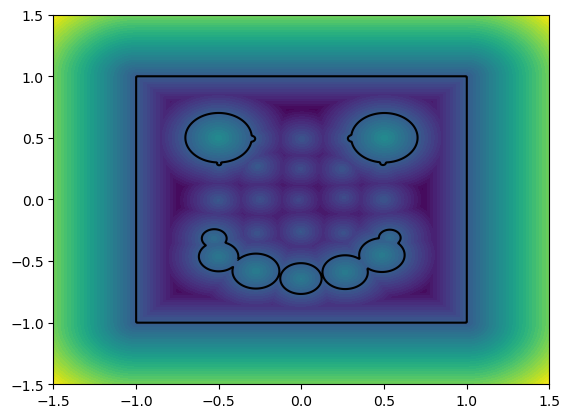

In [114]:
field = jax.vmap(to_opt_surface, in_axes=(None, 0))(to_opt_params, opt_loop_points).reshape(X.shape)

plt.contourf(X, Y, field, levels=50)
plt.contour(X, Y, field, levels=[to_opt_surface.level_set], colors='black')

In [76]:
final_grads

({'center': Array([1.1794803e-04, 5.1094583e-05], dtype=float32),
  'radius': Array(-0.00090822, dtype=float32)},
 {'center': Array([5.0186507e-05, 3.6682360e-04], dtype=float32),
  'radius': Array(-0.00083384, dtype=float32)},
 {'center': Array([9.2102655e-06, 7.9663505e-04], dtype=float32),
  'radius': Array(-0.00056628, dtype=float32)},
 {'center': Array([-2.0784240e-05,  4.7752704e-04], dtype=float32),
  'radius': Array(-0.00076647, dtype=float32)},
 {'center': Array([-0.0002843 ,  0.00026022], dtype=float32),
  'radius': Array(-0.00103202, dtype=float32)},
 {'center': Array([0.00016374, 0.00034154], dtype=float32),
  'radius': Array(-0.00035009, dtype=float32)},
 {'center': Array([-1.1522922e-07, -4.1222958e-07], dtype=float32),
  'radius': Array(3.148436e-07, dtype=float32)},
 {'center': Array([0., 0.], dtype=float32),
  'radius': Array(0., dtype=float32)},
 {'center': Array([0., 0.], dtype=float32),
  'radius': Array(0., dtype=float32)},
 {'center': Array([-0.00023383,  0.000130

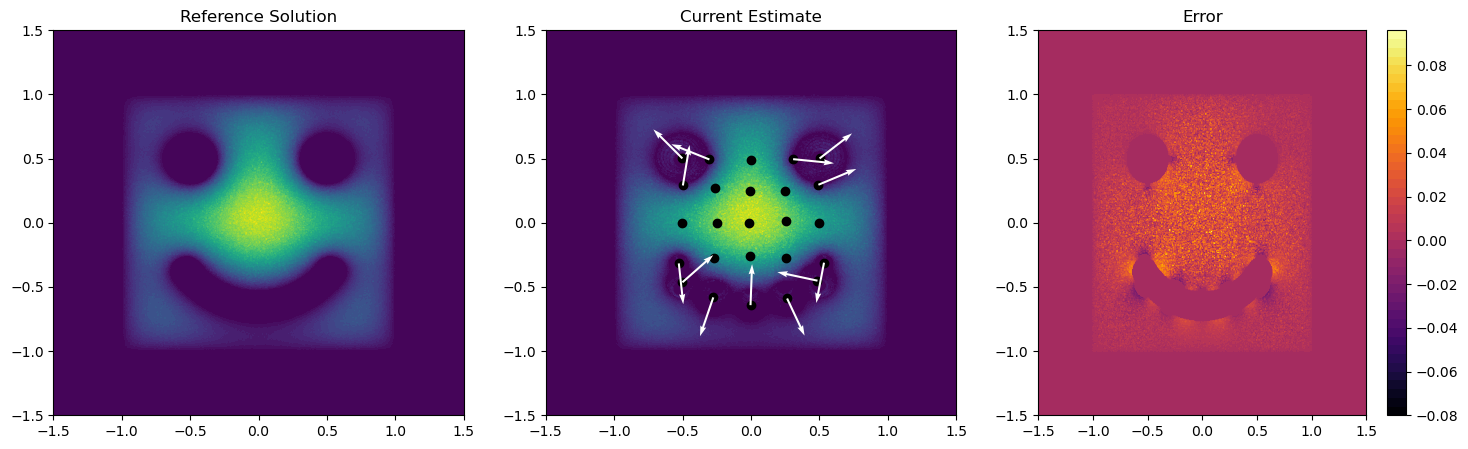

In [115]:
fig = plt.figure(figsize=(18, 5))
ax1 = fig.add_subplot(131)
contouf1 = ax1.contourf(X, Y, reference_estimate_full.squeeze().reshape(X.shape), levels=50)
ax1.set_title('Reference Solution')
ax2 = fig.add_subplot(132)
contouf2 = ax2.contourf(X, Y, u_solution_full.squeeze().reshape(X.shape), levels=50)
for dict in to_opt_params:
    center = dict['center']
    ax2.scatter(center[0], center[1], color='black')
for dict_grad, dict_val in zip(grad_surface, to_opt_params):
    grad_center = dict_grad['center']
    val_center = dict_val['center']
    if jnp.linalg.norm(grad_center) > 0:
        ax2.quiver(val_center[0], val_center[1], grad_center[0], grad_center[1], color='white', width=0.005, scale=float(jnp.linalg.norm(grad_center)* 10))

ax2.set_title('Current Estimate')
ax3 = fig.add_subplot(133)
error = jnp.zeros((opt_loop_points.shape[0]))
error = error.at[intersection_mask].set((u_solution_full.squeeze() - reference_estimate_full.squeeze())[intersection_mask])
contouf3 = ax3.contourf(X, Y, error.reshape(X.shape), levels=50, cmap='inferno')
plt.colorbar(contouf3, ax=ax3)
ax3.set_title('Error')
plt.show()

In [90]:
jnp.linalg.norm(final_grads[0]['center'], axis=-1)

Array(0.00016787, dtype=float32)

In [ ]:
sphere_params = {'center': jnp.array([0.0, 0.0]), 'radius': 0.5}
sphere_grad = {'center': jnp.array([0.0, -0.5]), 'radius': jnp.array(0.0)}